# Decoding a held gesture, and what the LFP bands add

This notebook decodes which of seven gestures T11 was holding, from a 500 ms window of neural activity. It asks the two questions this dataset is uniquely placed to answer.

**Does decoding decay the way selectivity does?** The paper's motivating measurement is that gesture selectivity falls as a gesture is held longer, which is why the latch decoder exists. Notebook 01 reproduced that as a feature count. Here it becomes an accuracy.

**What do the five local field potential bands contribute?** This is the first dataset in the catalog to ship LFP, so the question has not been askable before. The Study emits threshold crossings, spike-band power and the bands as three separate types, so comparing them is a matter of changing one extractor.

The window is fixed at 500 ms and taken from the **end** of each hold, so the 1, 2 and 4 second conditions use the same amount of data and only the elapsed time since gesture onset varies. Averaging over the whole hold instead would make a 4 second hold look better simply for being less noisy.

In [1]:
import matplotlib.pyplot as plt
import neuralset as ns
import numpy as np
import torch
import torch.nn as nn

from neuralshed.datasets.gusman_2025 import utils
from neuralshed.datasets.gusman_2025.study import Gusman2025DragAndDrop
from neuralshed.datasets.utils import dataset_dir
from neuralshed.extractors import NeuralFeatureExtractor

torch.manual_seed(0)

FS = utils.FS
WINDOW_S = 0.5
HOLDS = (1.0, 2.0, 4.0)

## One Gesture Hero session

T11's first, 420 trials over seven gestures, 20 per gesture at each of the three hold durations. Gesture Hero is the open-loop task, so nothing on screen depended on the neural signal and the labels are what was cued rather than what was decoded.

In [2]:
study = Gusman2025DragAndDrop(path=str(dataset_dir("gusman_2025") / "data"),
                              query="timeline_index == 2")
events = study.run()
print(f"session: {events.session.unique().tolist()}")
print(f"events: {len(events)}  types: {dict(events.type.value_counts())}")

segmenter = ns.dataloader.Segmenter(
    extractors={
        "tx": NeuralFeatureExtractor(target_unit="native", frequency=FS, event_types="SpikeCounts"),
        "sbp": NeuralFeatureExtractor(target_unit="native", frequency=FS, event_types="BandPower"),
        "lfp": NeuralFeatureExtractor(target_unit="native", frequency=FS, event_types="BandPower"),
    },
    trigger_query="type == 'Action' and action_kind == 'gesture_hold'",
    duration=None,
)
segments = segmenter.apply(events)
segments.prepare()
segments.pad_duration = "auto"
batch = segments.load_all()
triggers = batch.triggers.reset_index(drop=True)

print()
print({key: tuple(value.shape) for key, value in batch.data.items()})
print(f"holds: {triggers.hold_s.value_counts().sort_index().to_dict()}")

2026-08-24 15:41:56 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


session: ['T11_gesture_hero_s1']
events: 843  types: {'Stimulus': np.int64(420), 'Action': np.int64(420), 'SpikeCounts': np.int64(1), 'BandPower': np.int64(1), 'LfpBandPower': np.int64(1)}


2026-08-24 15:42:02 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


2026-08-24 15:42:08 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor



{'tx': (420, 192, 202), 'sbp': (420, 192, 202), 'lfp': (420, 960, 202)}
holds: {1.0: 140, 2.0: 140, 4.0: 140}


Segments are padded to the longest trial, so each one is sliced back to its own length before taking the final 500 ms. That is the same trap as in `willsey_2025`, where reading the last sample of a padded segment silently read padding.

In [3]:
n_window = int(WINDOW_S * FS)

def tail_window(key):
    """Mean over the last 500 ms of each trial's own span, as (n_trials, n_rows)."""
    data = batch.data[key].numpy()
    out = []
    for row in range(data.shape[0]):
        length = int(round(float(triggers.duration.iloc[row]) * FS))
        out.append(data[row, :, length - n_window : length].mean(axis=1))
    return np.array(out)


features = {key: tail_window(key) for key in ("tx", "sbp", "lfp")}
features["all"] = np.concatenate([features[k] for k in ("tx", "sbp", "lfp")], axis=1)
for name, block in features.items():
    print(f"{name:4s} {block.shape}")

tx   (420, 192)
sbp  (420, 192)
lfp  (420, 960)
all  (420, 1344)


## Labels and the split

The label is a column of `batch.triggers`. The split is by **block**, not by trial: the features were z-scored against a rolling 3 minute window before release, so trials near each other in time share normalization statistics, and a random split would leak through them. Five folds over the ten blocks gives every trial a prediction from a model that never saw its block.

In [4]:
labels = triggers.gesture.to_numpy()
classes = sorted(set(labels))
y = np.array([classes.index(name) for name in labels])
blocks = triggers.block.to_numpy()
holds = triggers.hold_s.to_numpy()

unique_blocks = sorted(set(blocks))
folds = [set(unique_blocks[i::5]) for i in range(5)]
print(f"{len(classes)} gestures, chance {100 / len(classes):.1f}%")
print(f"blocks: {unique_blocks}")
print(f"folds: {[sorted(f) for f in folds]}")

7 gestures, chance 14.3%
blocks: [np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0)]
folds: [[np.float64(3.0), np.float64(8.0)], [np.float64(4.0), np.float64(9.0)], [np.float64(5.0), np.float64(10.0)], [np.float64(6.0), np.float64(11.0)], [np.float64(7.0), np.float64(12.0)]]


## The model

A single linear layer on the window mean, which is multinomial logistic regression. Deliberately the smallest thing that works: with 420 trials and up to 1,344 inputs, anything larger would be fitting the split rather than the signal, and the comparison across feature sets only means something if the model is held fixed.

In [5]:
def cross_validated(block, epochs=200):
    """Leave-one-fold-out predictions for every trial."""
    predicted = np.zeros(len(y), dtype=int)
    for fold in folds:
        test = np.isin(blocks, list(fold))
        train = ~test
        mean = block[train].mean(0)
        std = block[train].std(0) + 1e-6
        x_train = torch.tensor((block[train] - mean) / std, dtype=torch.float32)
        x_test = torch.tensor((block[test] - mean) / std, dtype=torch.float32)
        y_train = torch.tensor(y[train])

        model = nn.Linear(block.shape[1], len(classes))
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-1)
        loss_fn = nn.CrossEntropyLoss()
        for _ in range(epochs):
            optimizer.zero_grad()
            loss_fn(model(x_train), y_train).backward()
            optimizer.step()
        with torch.no_grad():
            predicted[test] = model(x_test).argmax(1).numpy()
    return predicted


predictions = {name: cross_validated(block) for name, block in features.items()}
print("done")

done


## Results

Both questions answered in one table.

In [6]:
print(f"{'features':9s} {'inputs':>7s} " + "  ".join(f"{h:.0f}s hold" for h in HOLDS) + "   overall")
rows = {}
for name, predicted in predictions.items():
    per_hold = [(predicted[holds == h] == y[holds == h]).mean() for h in HOLDS]
    rows[name] = per_hold
    print(
        f"{name:9s} {features[name].shape[1]:7d} "
        + "  ".join(f"{value:8.1%}" for value in per_hold)
        + f"  {(predicted == y).mean():8.1%}"
    )
print(f"\nchance {1 / len(classes):.1%}, {len(y)} trials, 5-fold block cross-validation")

features   inputs 1s hold  2s hold  4s hold   overall
tx            192    62.1%     39.3%     35.7%     45.7%
sbp           192    61.4%     50.7%     37.1%     49.8%
lfp           960    58.6%     40.7%     37.9%     45.7%
all          1344    67.1%     42.9%     42.1%     50.7%

chance 14.3%, 420 trials, 5-fold block cross-validation


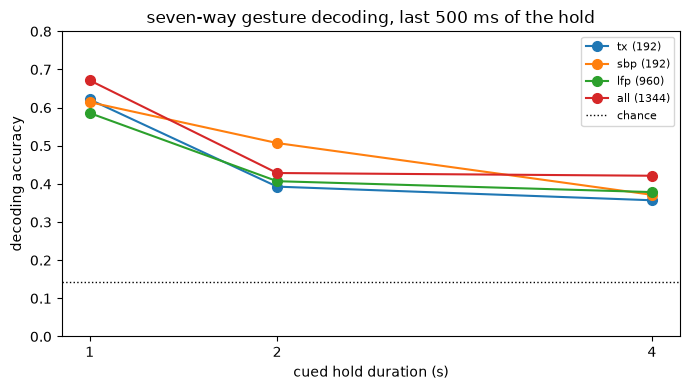

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, per_hold in rows.items():
    ax.plot(HOLDS, per_hold, "o-", ms=7, label=f"{name} ({features[name].shape[1]})")
ax.axhline(1 / len(classes), color="k", ls=":", lw=1, label="chance")
ax.set(xlabel="cued hold duration (s)", ylabel="decoding accuracy", xticks=HOLDS,
       title="seven-way gesture decoding, last 500 ms of the hold")
ax.set_ylim(0, 0.8)
ax.legend(fontsize=8)
plt.tight_layout()

Two readings.

**Decoding decays with hold duration for every feature set.** That is the paper's motivating observation reproduced as an accuracy rather than a feature count, and it is why a per-timestep classifier is the wrong tool for dragging: by four seconds into a hold, the thing you are classifying has largely stopped being distinctive.

**The LFP bands carry real gesture information on their own.** Five bands of band power, with no spiking input at all, decode close to what threshold crossings manage. That is worth knowing because LFP is more stable across days than threshold crossings, and because nothing else in the catalog could have shown it.

## Where the errors go

T11's seven gestures include `Left thumb - down` and `Right thumb - down`, which differ only by which hand. Both arrays are in the **left** hemisphere, so the left-hand gesture is ipsilateral. If the representation were dominated by which hand rather than which gesture, that pair would be the easy one and everything else would confuse.

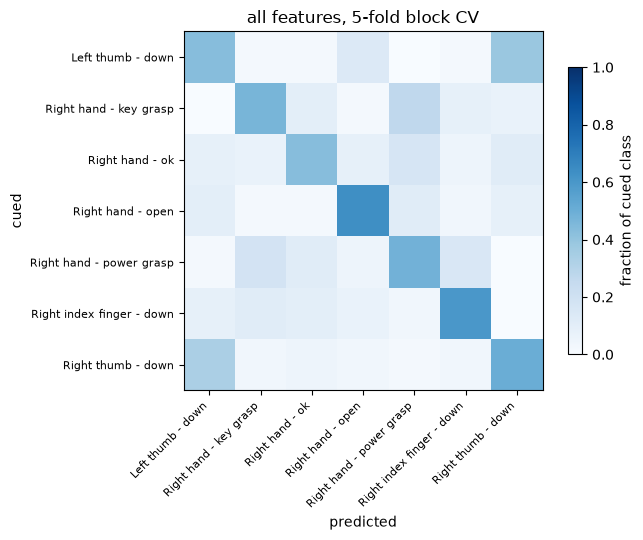

In [8]:
predicted = predictions["all"]
best_names = np.array(classes)

matrix = np.zeros((len(classes), len(classes)))
for p, t in zip(predicted, y):
    matrix[t, p] += 1
matrix = matrix / matrix.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(len(classes)), yticks=range(len(classes)),
       xlabel="predicted", ylabel="cued", title="all features, 5-fold block CV")
ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(classes, fontsize=8)
fig.colorbar(image, ax=ax, label="fraction of cued class", shrink=0.8)
plt.tight_layout()

In [9]:
left = classes.index("Left thumb - down")
right = classes.index("Right thumb - down")
print(f"left thumb  -> correct {matrix[left, left]:.1%},  called right thumb {matrix[left, right]:.1%}")
print(f"right thumb -> correct {matrix[right, right]:.1%}, called left thumb {matrix[right, left]:.1%}")
print()
off = matrix.copy()
np.fill_diagonal(off, 0)
print(f"mean off-diagonal confusion: {off[off > 0].mean():.1%}")
print(f"the thumb pair, both directions: {(matrix[left, right] + matrix[right, left]) / 2:.1%}")

left thumb  -> correct 43.3%,  called right thumb 38.3%
right thumb -> correct 50.0%, called left thumb 33.3%

mean off-diagonal confusion: 9.1%
the thumb pair, both directions: 35.8%


It is the other way round. The thumb pair confuses at **35.8%**, against a mean off-diagonal confusion of **9.1%** across every other pair, so it is roughly four times harder than an average mistake. Left thumb is called right thumb 38.3% of the time, almost as often as it is called correctly.

So from these two left-hemisphere arrays, *which gesture* is much better represented than *which hand performs it*. That lines up with what `deo_2024` measured directly, ipsilateral tuning suppressed 34% against 12% for contralateral, and it is the observation `jude_2026_typing` answers by implanting both hemispheres. Three datasets in the catalog, one open question and its answer.

## Honest reading, and what was left on the table

The accuracies are cross-validated over blocks and every trial is predicted by a model that never saw its block, so they are not inflated by a leaky split. They are still one session, one participant and one seed.

The comparison across feature sets is the part to trust least in absolute terms. The four sets have very different input dimensionalities, 192 against 960 against 1,344, and a linear model with fixed weight decay does not treat those equally. The ordering is informative, the exact gaps less so.

Levers deliberately not pulled:

- **One session and one participant.** T11 has a second Gesture Hero session and T5 has one, and neither is used. Pooling them is possible here, unlike in `vargas_2025`, because the channel axis is identified.
- **Window mean only.** The 500 ms window is collapsed to its average, throwing away the temporal shape that a convolution would use.
- **No per-band breakdown.** The five LFP bands are pooled into one 960-input block, so which band carries the information is not answered.
- **The drag-and-drop sessions are untouched.** They hold the closed-loop stages and the latch decoder's own output, which would support asking how a decoder trained on held gestures transfers to gestures held during cursor movement.